# Xenium–MACSima Single-Core Co-Registration

This notebook demonstrates how to co-register a single tissue core imaged by two
complementary spatial technologies:

| Technology | What it measures | Pixel size |
|---|---|---|
| **10x Xenium** | Targeted spatial transcriptomics (gene expression per cell) | ~200 nm |
| **MACSima** | Highly multiplexed cyclic protein imaging (50+ markers) | ~130 nm |

By aligning these modalities on the same tissue core, every cell gains both a
**transcriptomic profile** and a **protein expression profile** — enabling
multi-modal single-cell analysis at subcellular resolution.

## Strategy

1. Both instruments image the same TMA (tissue microarray) slide independently,
   producing separate coordinate systems.
2. Both instruments capture a nuclear DAPI channel.  We use SIFT-based feature
   matching to find the affine transform that maps the MACSima DAPI image onto the
   Xenium morphology-focus nuclear channel (the *target*).
3. The recovered affine is applied to all MACSima protein channels, bringing
   them into Xenium's coordinate space.
4. The result is a `SpatialData` object containing aligned images, cell
   segmentation boundaries, the transcriptomic cell table (with cell-type
   annotations), and raw transcript coordinates — ready for joint analysis.

## Prerequisites

Run `Copy_data.ipynb` first to prepare the two input resources used here:
- `data/annot_xenium/adata_position_<POSITION>.h5ad` — cell-type annotations for the target core
- `data/macsima/ROI<ROI>/` — pre-copied MACSima channel images for the matching ROI


In [ ]:
# bsub -R "rusage[mem=200G]" -q verylong -oo /omics/odcf/analysis/OE0260_projects/spatial/jakob/registration_xenium_macsima_amplify/reg_sharing/code/00_align_one_core.log \
# bash -c 'source /omics/groups/OE0260/internal/jakob/miniforge-pypy3/bin/activate && conda activate /home/j548r/mamba_envs/spatial && ipython -c "%run /omics/odcf/analysis/OE0260_projects/spatial/jakob/registration_xenium_macsima_amplify/reg_sharing/code/00_align_one_core.ipynb"'

# Standard library
import os
import sys

# Numeric / image processing
import numpy as np
import tifffile
import dask
dask.config.set({'dataframe.query-planning': False})     # required by spatialdata

# Single-cell analysis
import scanpy as sc

# Spatial data framework
import spatialdata as sd
import spatialdata_io
import dask_image

# Visualisation
import matplotlib.pyplot as plt

# Add the shared registration module to the Python path
sys.path.append(
    '/omics/odcf/analysis/OE0260_projects/spatial/jakob/registration_xenium_macsima_amplify/reg_sharing/example_code_full_slide/'
)
from xenium_macsima_core_registration import XeniumMacsimaRegistration, preprocess_reg

print("✓ All imports successful")


/home/j548r/mamba_envs/spatial/lib/python3.11/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/j548r/mamba_envs/spatial/lib/python3.11/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


✓ All imports successful


## Paths and Parameters

Two key identifiers connect the same tissue core across the two instruments:

- **POSITION** — the Xenium TMA core index (a float-valued string such as `'1.0'`)
- **ROI_INDEX** — the matching MACSima region-of-interest number

The mapping between positions and ROIs was established manually by comparing
the physical slide layout with each instrument's scan pattern
(see the companion notebook `00_match_rois_cores.ipynb` for details).

All large raw Xenium files (morphology-focus TIFF stack, transcript parquet,
cell/nucleus boundaries) are read directly from the Xenium output folder.
The cell-type annotations and the MACSima images are read from the local
`data/` directory, which was populated by `Copy_data.ipynb`.


In [ ]:

# ── Target core ───────────────────────────────────────────────────────────────
POSITION  = '1.0'   # Xenium TMA position index for this core
ROI_INDEX = 40      # Matching MACSima ROI number

# ── Registration scale factor ─────────────────────────────────────────────────
# Both SIFT images are down-scaled by this factor before feature detection.
# Larger values reduce run time but may miss fine details; 3 is a good default.
SCALE_FACTOR = 3

# ── Input paths (all under the local data/ directory) ─────────────────────────
# These files were produced by Copy_data.ipynb.
# No access to the original large datasets is required to run this notebook.
DATA_DIR   = '/omics/odcf/analysis/OE0260_projects/spatial/jakob/registration_xenium_macsima_amplify/reg_sharing/data'
ANNOT_H5AD = f'{DATA_DIR}/annot_xenium/adata_position_{POSITION}.h5ad'

# Xenium-derived data for this core (pre-extracted by Copy_data.ipynb)
RAW_DIR            = f'{DATA_DIR}/raw_xenium'
DX_H5AD            = f'{RAW_DIR}/dx_position_{POSITION}.h5ad'
BBOX_FILE          = f'{RAW_DIR}/bbox_position_{POSITION}.npy'
TF_FILE            = f'{RAW_DIR}/transform_factor_position_{POSITION}.npy'
MF_ROI_FILE        = f'{RAW_DIR}/mf_roi_position_{POSITION}.tif'
MF_FULL_ROI_FILE   = f'{RAW_DIR}/mf_full_roi_position_{POSITION}.tif'
CELL_BOUNDS_FILE   = f'{RAW_DIR}/cell_boundaries_position_{POSITION}.parquet'
NUC_BOUNDS_FILE    = f'{RAW_DIR}/nucleus_boundaries_position_{POSITION}.parquet'
TRANSCRIPTS_FILE   = f'{RAW_DIR}/transcripts_position_{POSITION}.parquet'

# MACSima image folder for this ROI (copied by Copy_data.ipynb)
MACSIMA_FOLDER = f'{DATA_DIR}/macsima/ROI{ROI_INDEX}/'

# ── Output ────────────────────────────────────────────────────────────────────
OUTPUT_ZARR = (
    '/omics/odcf/analysis/OE0260_projects/spatial/MACSima_amplify/'
    f'aligned_objects/Slide_TMAN2-1-1/Pos_{POSITION}_ROI_{ROI_INDEX}.zarr'
)

print(f"Target core  : Xenium position {POSITION}  →  MACSima ROI {ROI_INDEX}")
print(f"Scale factor : {SCALE_FACTOR}")
print(f"Data dir     : {DATA_DIR}")
print(f"Output       : {OUTPUT_ZARR}")


Target core  : Xenium position 1.0  →  MACSima ROI 40
Scale factor : 3
Data dir     : ../data
Output       : /omics/odcf/analysis/OE0260_projects/spatial/MACSima_amplify/aligned_objects/Slide_TMAN2-1-1/Pos_1.0_ROI_40.zarr


## Step 1 — Load Cell-Type Annotations

`Copy_data.ipynb` extracted the cells belonging to this specific TMA core from
the complete multi-slide dataset and stored them with their Xenium cell identifiers
(`obs_name_orig`) and hierarchical cell-type labels.

Loading this small, pre-filtered file is much faster than reading the complete
annotated object and keeps this notebook self-contained.

The annotations include three levels of cell-type resolution, plus nuclear and
cellular morphology measurements (areas and centroids) that will be used in
Step 4 to determine the ROI bounding box for image cropping.


In [ ]:

# Load the pre-filtered annotated data for this core.
# Every cell in this file belongs to POSITION, is within a TMA core boundary,
# and carries cell-type annotations from the upstream clustering pipeline.
adata = sc.read_h5ad(ANNOT_H5AD)

# Copy_data.ipynb saved the annotations before align_data_tables() ran, so
# obs_names still carry the original AnnData index rather than the Xenium cell
# IDs (obs_name_orig).  The registration module's transform_boundaries() method
# checks `if name not in self.adata.obs_names` to decide which polygons to
# transform — if obs_names don't match the boundary index the boundaries are
# silently skipped and end up in the wrong coordinate system.
adata.obs_names = adata.obs['obs_name_orig'].astype(str)

print(f"Loaded {adata.n_obs} cells from Xenium position {POSITION}")
print(f"\nCell-type composition (level 1):")
print(adata.obs['cell_type_lvl_1'].value_counts().to_string())


Loaded 13136 cells from Xenium position 1.0

Cell-type composition (level 1):
cell_type_lvl_1
MES1                    3858
Myeloid                 2338
NPC-like                2086
Proliferation            837
Oligodendrocytes         809
Endothelial_cells        613
Perivascular_cells_1     500
AC-like                  449
OPC-like                 408
Astrocytes               338
Neurons                  275
MES2                     224
Immune_adjacent          215
T_cells                  140
Perivascular_cells_2      46


## Step 2 — Reconstruct the Registration State from Pre-Saved Files

`Copy_data.ipynb` ran the slow steps (reading the full Xenium output folder, aligning
cell tables, computing the bounding box) and saved everything needed here as small,
self-contained files.

We reconstruct the `XeniumMacsimaRegistration` object by:
1. Loading `dx` — the Xenium cell table already filtered to this core, with
   `obsm['spatial']` (Xenium pixel coordinates) and `obsm['spatial_transformed']`
   (down-scaled image coordinates) pre-populated.
2. Loading `bbox` and `transform_factor` — geometric metadata derived from the
   cell coordinate distribution.
3. Loading cell/nucleus boundary polygons from GeoParquet.
4. Loading the pre-filtered transcript table.
5. Assembling a lightweight `SpatialData` container from these pieces and
   setting it as `registration.xenium_data`.

After this step the `registration` object is in exactly the same state as it
would be after `load_xenium_data()` + `align_data_tables()` + `calculate_roi_bbox()`,
but **without ever opening the original Xenium folder**.


In [ ]:

import geopandas as gpd
import pandas as pd
from spatialdata.models import ShapesModel, PointsModel
from spatialdata.transformations import Identity, set_transformation

# ── Initialise the pipeline ───────────────────────────────────────────────────
registration = XeniumMacsimaRegistration(scale_factor=SCALE_FACTOR)

# Inject annotations (Step 1 output)
registration.adata = adata

# ── Load pre-saved Xenium metadata ────────────────────────────────────────────
# Xenium cell table (expression matrix + per-cell spatial coordinates)
dx = sc.read_h5ad(DX_H5AD)
print(f"✓ Loaded dx: {dx.n_obs} cells, {dx.n_vars} genes")
print(f"  obsm keys: {list(dx.obsm.keys())}")

# Geometric metadata computed during the Copy_data run
registration.transform_factor = float(np.load(TF_FILE)[0])
registration.bbox              = tuple(np.load(BBOX_FILE))
bbox = registration.bbox
print(f"\n✓ Transform factor (µm per pixel): {registration.transform_factor:.4f}")
print(f"✓ Bounding box (down-scaled px)  : "
      f"x=[{bbox[0]:.0f}, {bbox[2]:.0f}]  y=[{bbox[1]:.0f}, {bbox[3]:.0f}]")

# ── Load boundaries ───────────────────────────────────────────────────────────
# Cell and nucleus polygons are stored as GeoParquet files.
# ShapesModel.parse() registers them in the spatialdata format.
cell_bounds = ShapesModel.parse(gpd.read_parquet(CELL_BOUNDS_FILE))
nuc_bounds  = ShapesModel.parse(gpd.read_parquet(NUC_BOUNDS_FILE))
print(f"\n✓ Cell boundaries   : {len(cell_bounds)} polygons")
print(f"✓ Nucleus boundaries: {len(nuc_bounds)} polygons")

# ── Load transcripts ──────────────────────────────────────────────────────────
# Transcripts are stored in the original Xenium coordinate system (µm) so that
# add_table_and_transcripts() can apply its bounding-box filter and shift.
transcripts_df = pd.read_parquet(TRANSCRIPTS_FILE)
# PointsModel wraps the DataFrame in the spatialdata points format.
transcripts_sd = PointsModel.parse(
    transcripts_df,
    coordinates={'x': 'x', 'y': 'y'},
)
set_transformation(transcripts_sd, Identity(), 'global')
print(f"\n✓ Transcripts loaded: {len(transcripts_df):,} molecules")

# ── Assemble a minimal SpatialData to hold the pre-loaded elements ────────────
# We do NOT load the full Xenium output folder; instead we build a lightweight
# SpatialData containing only what the remaining pipeline steps need.
xenium_data_minimal = sd.SpatialData(
    shapes={
        'cell_boundaries'    : cell_bounds,
        'nucleus_boundaries' : nuc_bounds,
    },
    points={
        'transcripts': transcripts_sd,
    },
)
registration.xenium_data = xenium_data_minimal
print(f"\n✓ Minimal SpatialData assembled (no original Xenium folder needed)")


✓ Loaded dx: 13136 cells, 5101 genes
  obsm keys: ['spatial', 'spatial_transformed']

✓ Transform factor (µm per pixel): 4.7059
✓ Bounding box (down-scaled px)  : x=[13614, 16342]  y=[25731, 28389]

✓ Cell boundaries   : 13136 polygons
✓ Nucleus boundaries: 13136 polygons
INFO     Column `z` in `data` will be ignored since the data is 2D.                                                

✓ Transcripts loaded: 12,979,354 molecules

✓ Minimal SpatialData assembled (no original Xenium folder needed)


## Step 3 — Load Images

Two images serve as registration inputs:

| Image | Role | Source |
|---|---|---|
| **Xenium morphology focus (ROI crop)** | *Target* — align **to** this image | `data/raw_xenium/mf_roi_position_*.tif` |
| **MACSima DAPI** | *Source* — align **from** this image | `data/macsima/ROI*/C-000_…_DAPI_….tif` |

Both files were produced by `Copy_data.ipynb`:
- **`mf_roi`** is a pre-cropped, pre-processed (CLAHE + uint8) version of channel 0
  (DAPI) of the Xenium morphology-focus image, cropped to the bounding box of this
  core.  Loading it here is instantaneous and does not require the original
  ~GB morphology-focus file.
- **MACSima DAPI** is read from the local `data/macsima/ROI*/` folder.

**MACSima file naming convention:**
`C-<cycle>_S-<sample>_<S|B>_<fluorophore>_…_A-<antibody>.tif`
- `C-000` — baseline cycle (DAPI only, no antibody yet)
- `S` prefix — single-stain exposure (vs. `B` for background frame)


In [ ]:

# ── Xenium morphology focus (pre-cropped) ─────────────────────────────────────
# Copy_data.ipynb pre-processed and cropped the Xenium nuclear channel to this
# core's bounding box and saved it as a small TIFF.  We load that file directly
# so the large (~GB) morphology_focus_0000.ome.tif is never needed here.
mf_roi = tifffile.imread(MF_ROI_FILE)
print(f"✓ Morphology focus ROI (SIFT-ready)  : {mf_roi.shape}  dtype={mf_roi.dtype}")

# ── MACSima DAPI ──────────────────────────────────────────────────────────────
# Identify the cycle-0 single-exposure DAPI file in the local MACSima data.
# Exclude background frames (marked with '_S_' for single vs '_B_' for background).
dapi_candidates = [
    f for f in os.listdir(MACSIMA_FOLDER)
    if 'DAPI' in f and 'C-000' in f and '_S_' in f
]
assert len(dapi_candidates) == 1, (
    f"Expected exactly one cycle-0 DAPI file, found: {dapi_candidates}"
)
MACSIMA_DAPI = os.path.join(MACSIMA_FOLDER, dapi_candidates[0])
print(f"\nMACSima DAPI file: {dapi_candidates[0]}")

print("Loading MACSima DAPI image …")
macsima_img = registration.load_macsima_image(MACSIMA_DAPI)
print(f"✓ MACSima image shape: {macsima_img.shape}")


✓ Morphology focus ROI (SIFT-ready)  : (2658, 2728)  dtype=uint8

MACSima DAPI file: C-000_S-000_S_DAPI_R-01_W-A-1_ROI-40_A-DAPI.tif
Loading MACSima DAPI image …
Loading MACSIMA image from ../data/macsima/ROI40/C-000_S-000_S_DAPI_R-01_W-A-1_ROI-40_A-DAPI.tif
✓ MACSima image shape: (10069, 12401)


## Step 4 — Image Registration

We use SIFT (Scale-Invariant Feature Transform) feature matching to estimate the
affine transform that maps the MACSima DAPI image onto the Xenium morphology-focus
nuclear channel (the *target*).

**Why SIFT works here:** Both instruments capture the same DAPI-stained nuclei.
SIFT finds scale- and rotation-invariant keypoints in both images and matches
them by descriptor similarity.  Lowe's ratio test (ratio < 0.7) discards ambiguous
matches; the surviving pairs are used to fit a 2-D affine transform.

**Pre-processing pipeline (same for both images):**
1. Down-scale by `SCALE_FACTOR` — speeds up detection and reduces photon noise
2. CLAHE contrast enhancement (`skimage.exposure.equalize_adapthist`)
3. Normalise to uint8 range

`Copy_data.ipynb` already applied this pipeline to the Xenium channel and saved
`mf_roi` — so here we pass it directly as the target.  For MACSima we apply the
same pipeline on the fly.

The recovered affine matrix is rescaled from down-scaled to full-resolution
coordinates and applied to the entire MACSima image stack with
`dask_image.ndinterp.affine_transform` (lazy, memory-efficient).


In [ ]:

# The bounding box and mf_roi were already computed by Copy_data.ipynb and
# loaded in Step 2 / Step 3.  We go straight to SIFT registration.
#
# register_images() returns:
#   affine_2d      – (2×3) affine at down-scaled resolution (used in QC plots)
#   affine_2d_full – (2×3) affine at full resolution (applied to all channels)
#   aligned_macsima – full MACSima DAPI stack after the transform (lazy Dask array)
print(f"Running SIFT registration  (MACSima DAPI  →  Xenium morphology focus ROI) …")
print(f"  Target shape : {mf_roi.shape}  (pre-processed Xenium nuclear channel)")
print(f"  Source shape : {macsima_img.shape}  (MACSima DAPI, to be aligned)")

affine_2d, affine_2d_full, aligned_macsima = registration.register_images(
    macsima_img, mf_roi
)
print("✓ Registration complete")
print(f"  Affine matrix at registration scale:\n{affine_2d}")


Running SIFT registration  (MACSima DAPI  →  Xenium morphology focus ROI) …
  Target shape : (2658, 2728)  (pre-processed Xenium nuclear channel)
  Source shape : (10069, 12401)  (MACSima DAPI, to be aligned)
Preprocessing MACSIMA image for registration
Computing alignment matrix
Applying transformation to full MACSIMA image
✓ Registration complete
  Affine matrix at registration scale:
[[ 1.24040610e+00 -1.10710924e-02  9.25554429e+01]
 [ 1.10710924e-02  1.24040610e+00  2.74480587e+02]]


## Step 5 — Registration Quality Check

Before assembling the full multi-modal object, we visually verify the alignment.

**Panel A** shows the Xenium morphology-focus (nuclear channel) with Xenium-derived
cell centroids overlaid in red.  These should sit on top of nuclear structures.

**Panel B** shows the aligned MACSima DAPI with the same centroids in cyan.  If
registration succeeded, nuclei in both panels should be in the same positions.

**Panel C** is a false-colour overlay:
- **Green** = Xenium morphology focus
- **Red** = aligned MACSima DAPI
- **Yellow / white** regions = good overlap between the two nuclear signals

> **If the overlay looks poor** (strong colour fringes, shifted nuclei), re-run
> Step 4 after adjusting `SCALE_FACTOR` or verifying the correct DAPI file was used.


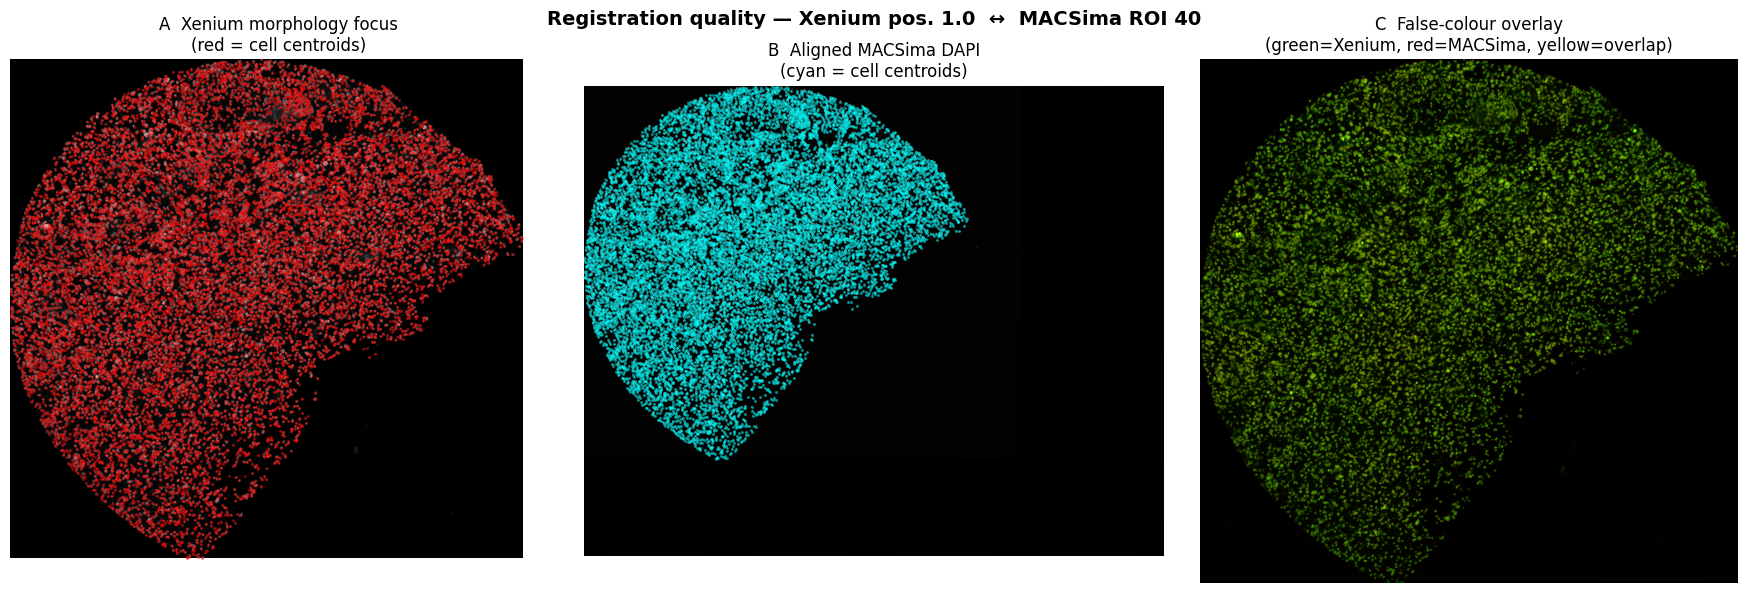

✓ Quality-check figure saved


In [ ]:

# Compute the aligned MACSima DAPI at registration scale for fast display.
# We apply preprocess_reg again so colour scales match the mf_roi panel exactly.
aligned_macsima_np = aligned_macsima.compute()      # materialise the Dask array
dna_macsima_proc   = preprocess_reg(aligned_macsima_np, SCALE_FACTOR)

# Cell centroid positions shifted to local (ROI-relative) pixel coordinates.
cx = dx.obsm['spatial_transformed'][:, 0] - bbox[0]
cy = dx.obsm['spatial_transformed'][:, 1] - bbox[1]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
fig.suptitle(
    f'Registration quality — Xenium pos. {POSITION}  ↔  MACSima ROI {ROI_INDEX}',
    fontsize=14, fontweight='bold'
)

# ── Panel A: Xenium target ────────────────────────────────────────────────────
axes[0].imshow(mf_roi, cmap='gray')
axes[0].scatter(cx, cy, s=4, c='red', alpha=0.6, linewidths=0)
axes[0].set_title('A  Xenium morphology focus\n(red = cell centroids)')
axes[0].axis('off')

# ── Panel B: Aligned MACSima DAPI ─────────────────────────────────────────────
axes[1].imshow(dna_macsima_proc, cmap='gray')
axes[1].scatter(cx, cy, s=4, c='cyan', alpha=0.6, linewidths=0)
axes[1].set_title('B  Aligned MACSima DAPI\n(cyan = cell centroids)')
axes[1].axis('off')

# ── Panel C: False-colour overlay ─────────────────────────────────────────────
min_h = min(mf_roi.shape[0], dna_macsima_proc.shape[0])
min_w = min(mf_roi.shape[1], dna_macsima_proc.shape[1])

def norm(arr):
    a = arr[:min_h, :min_w].astype(float)
    return (a - a.min()) / (a.max() - a.min() + 1e-8)

overlay          = np.zeros((min_h, min_w, 3), dtype=float)
overlay[:, :, 1] = norm(mf_roi)            # green = Xenium
overlay[:, :, 0] = norm(dna_macsima_proc)  # red   = MACSima

axes[2].imshow(overlay)
axes[2].set_title('C  False-colour overlay\n(green=Xenium, red=MACSima, yellow=overlap)')
axes[2].axis('off')

plt.tight_layout()
plt.savefig(
    f'registration_quality_Pos{POSITION}_ROI{ROI_INDEX}.png',
    dpi=200, bbox_inches='tight'
)
plt.show()
print("✓ Quality-check figure saved")


## Step 6 — Build the Aligned SpatialData Object

We now assemble a single `SpatialData` object that holds all modalities in a
shared coordinate system.

| Layer | Type | Description |
|---|---|---|
| `morphology_focus` | Image | Xenium nuclear channel (down-scaled), for structural context |
| `macsima_img` | Image | Aligned MACSima DAPI channel |
| `macsima_<channel>` | Image | All other MACSima protein-marker channels (same affine transform) |
| `cell_boundaries` | Shapes | Xenium cell segmentation polygons in ROI image coordinates |
| `nucleus_boundaries` | Shapes | Xenium nucleus segmentation polygons |
| `adata` | Table | AnnData cell table with expression data and cell-type annotations |
| `transcripts` | Points | Individual RNA molecule coordinates, cropped to the ROI |

All spatial layers share the `global` coordinate system, enabling interactive
exploration in tools such as **napari-spatialdata** and joint single-cell analyses.


In [ ]:

# ── Transform cell / nucleus boundaries ──────────────────────────────────────
# Xenium polygons are stored in µm-scale Xenium coordinates.  We map them to
# ROI image pixel coordinates by (1) multiplying by transform_factor to convert
# µm → Xenium pixels and (2) translating by the bounding-box origin so the
# polygons line up with the cropped images built below.
print("Transforming cell and nucleus boundaries to ROI image space …")
registration.transform_boundaries()
print("✓ Boundaries transformed")

# ── Load the full-resolution morphology focus crop ────────────────────────────
# Copy_data.ipynb saved a full-resolution crop of the Xenium nuclear channel
# covering exactly this core's bounding box.  We load it directly here —
# no need to reopen the large whole-slide morphology-focus file.
print("Loading full-resolution morphology focus crop …")
full_mf_roi = tifffile.imread(MF_FULL_ROI_FILE)
print(f"✓ Full-res morphology focus crop shape: {full_mf_roi.shape}")

# ── Create the base SpatialData object ───────────────────────────────────────
# Bundles the aligned MACSima DAPI, the morphology-focus crops (down-scaled for
# SIFT context; full-res for structural reference), and the transformed
# boundaries into a new SpatialData container.
print("Creating base SpatialData object …")
aligned_data = registration.create_aligned_spatialdata(
    aligned_macsima=aligned_macsima,
    mf_roi=mf_roi,
    full_mf=full_mf_roi,
)
print(f"✓ Image layers  : {list(aligned_data.images.keys())}")
print(f"✓ Shape layers  : {list(aligned_data.shapes.keys())}")


Transforming cell and nucleus boundaries to ROI image space …
✓ Boundaries transformed
Loading full-resolution morphology focus crop …
✓ Full-res morphology focus crop shape: (7974, 8185)
Creating base SpatialData object …
Creating aligned SpatialData object


In [ ]:

# ── Add all MACSima protein channels ─────────────────────────────────────────
# Every TIFF in the MACSima folder (except the DAPI used for registration) is
# transformed with the same affine matrix computed in Step 4 and stored as a
# separate image layer.  Channel names are derived from the antibody encoded in
# each filename (e.g. 'CD8a', 'FoxP3', 'Vimentin').
# Set max_images to a small integer (e.g. 3) when testing to speed things up.
print("Adding all MACSima protein channels (this may take several minutes) …")
registration.add_additional_macsima_images(
    aligned_data,
    MACSIMA_FOLDER,
    affine_2d_full,
    max_images=None,    # None = add every available channel
)
print(f"\n✓ Total image layers: {len(aligned_data.images)}")

# ── Add the annotated cell table and filtered transcripts ─────────────────────
# The cell-type–annotated AnnData (dx with joined labels) is registered against
# the 'cell_boundaries' shape layer, so that spatialdata can link cells to their
# polygon geometries.
# Transcripts are spatially filtered to the ROI bounding box and their
# coordinates are shifted to local (ROI-relative) image space.
print("\nAdding annotated cell table and filtered transcripts …")
registration.add_table_and_transcripts(aligned_data, dx)
print(f"✓ Cell table    : {aligned_data.tables['adata'].n_obs} cells, "
      f"{aligned_data.tables['adata'].n_vars} features")
print(f"✓ Transcripts   : {len(aligned_data['transcripts'])} molecules in ROI")
print(f"\nFinal SpatialData summary:\n{aligned_data}")


Adding all MACSima protein channels (this may take several minutes) …
Adding additional MACSIMA images (max: all)
Found 30 total images, processing 28 images
Adding image 1/28: macsima_C-006_S-000_S_APC_R-01_W-A-1_ROI-40_A-Cytokeratin7_C-REA935
Adding image 2/28: macsima_C-002_S-000_S_FITC_R-01_W-A-1_ROI-40_A-CD8a_C-REA1024
Adding image 3/28: macsima_C-005_S-000_S_PE_R-01_W-A-1_ROI-40_A-CD274


KeyboardInterrupt: 

## Step 7 — Save the Aligned Object

The assembled `SpatialData` object is serialised as a **Zarr store** — a
directory-based, chunked format that supports lazy I/O and is the native on-disk
representation for `spatialdata`.

The output path encodes both the Xenium position and the MACSima ROI number so
that multiple cores can be processed in parallel and their outputs remain
unambiguously identifiable.

After saving, the object can be:
- **Re-opened** with `sd.read_zarr(output_path)` in any downstream notebook
- **Visualised** interactively with `napari-spatialdata`
- **Analysed** jointly for protein–RNA co-expression at single-cell resolution


In [ ]:

OUTPUT_ZARR = '/omics/odcf/analysis/OE0260_projects/spatial/jakob/registration_xenium_macsima_amplify/reg_sharing/data/output/Pos_1.0_ROI_40.zarr'
os.makedirs(os.path.dirname(OUTPUT_ZARR), exist_ok=True)

print(f"Saving aligned SpatialData to:\n  {OUTPUT_ZARR}")
aligned_data.write(
    OUTPUT_ZARR,
    overwrite=True,
    consolidate_metadata=True,   # writes a single .zmetadata file for fast opens
)
print("✓ Save complete")

# ── Summary ───────────────────────────────────────────────────────────────────
print("\n" + "=" * 60)
print("  REGISTRATION PIPELINE COMPLETE")
print("=" * 60)
print(f"  Xenium position  :  {POSITION}")
print(f"  MACSima ROI      :  {ROI_INDEX}")
print(f"  Cells aligned    :  {aligned_data.tables['adata'].n_obs}")
print(f"  Image layers     :  {len(aligned_data.images)}")
print(f"  Output           :  {OUTPUT_ZARR}")
print("=" * 60)


Saving aligned SpatialData to:
  /omics/odcf/analysis/OE0260_projects/spatial/jakob/registration_xenium_macsima_amplify/reg_sharing/data/output/Pos_1.0_ROI_40.zarr
INFO     The Zarr backing store has been changed from None the new file path:                                      
         /omics/odcf/analysis/OE0260_projects/spatial/jakob/registration_xenium_macsima_amplify/reg_sharing/data/ou
         tput/Pos_1.0_ROI_40.zarr                                                                                  
✓ Save complete

  REGISTRATION PIPELINE COMPLETE
  Xenium position  :  1.0
  MACSima ROI      :  40


KeyError: 'adata'

The .zarr file can be viewed with napari (using the spatialdata plugin)
https://spatialdata.scverse.org/projects/napari/en/latest/notebooks/spatialdata.html